# 03 · Fine-tune mô hình VSL với dữ liệu tăng cường mới

Cập nhật ensemble đã train (`runs/<run>/ensemble.pt`) bằng dataset mới có **nhiều mẫu hơn** (thường do
`augment_features.ipynb` sinh thêm) nhưng **giữ nguyên danh sách lớp**. Không train lại từ đầu:

- Mỗi model (từng fold + model toàn bộ dữ liệu) được **warm-start** từ trọng số cũ, cùng kiến trúc và cùng `Config`.
- LR nhỏ (`FT_LR_SCALE` × LR gốc), warmup 1 epoch, ít epoch, dừng sớm nhanh → thường chỉ tốn ~10–20% thời gian train gốc.
- Model ban đầu được chấm trên val **trước** epoch 1 và là ứng viên "best": fine-tune không thể trả về model tệ hơn trên val.
- `NORM_MODE="keep"` giữ mean/std cũ của từng model → trọng số không bị lệch phân phối đầu vào.

**Chống rò rỉ (bắt buộc).** Model fold *f* đã thấy mọi mẫu gốc ngoài fold *f*. Vì vậy group gốc cũ phải **giữ đúng fold cũ**
(đọc từ `folds.json` của run gốc); group gốc mới chưa model nào thấy nên được xếp vào fold nào cũng an toàn. Bản tăng cường đi
theo group của mẫu gốc, và validation/OOF chỉ chấm mẫu gốc. Run cũ chưa có `folds.json` thì phép chia được tính lại giống
`train.ipynb` — chỉ chính xác khi tập mẫu **gốc** không đổi (chỉ thêm bản tăng cường).

**Chế độ nhanh (`FAST=True`, mặc định) — khi chỉ thêm mẫu cho vài lớp.** So với run gốc, notebook tự tìm mẫu **mới**
(`samples.json` của run gốc; run cũ chưa có thì so thời điểm tạo mẫu với thời điểm chạy run gốc) và lớp chứa chúng:
- Mỗi epoch chỉ train trên **mọi mẫu mới + `REPLAY_PER_CLASS` mẫu cũ mỗi lớp** rút ngẫu nhiên (đổi mỗi epoch, nên qua các epoch
  vẫn ôn được phần lớn dữ liệu cũ). Lớp có mẫu mới và lớp hay bị nhầm với chúng được ôn gấp `FOCUS_REPLAY_SCALE` lần.
- Trọng số loss được bù theo tỉ lệ rút mẫu, nên kỳ vọng loss vẫn bằng loss trên toàn bộ dữ liệu: lớp được ôn nhiều không bị thiên vị.
- Fold nào có tập train **không có mẫu mới** thì giữ nguyên model gốc (không train).
- Validation vẫn chấm **toàn bộ** mẫu gốc của fold, và model ban đầu vẫn là ứng viên "best" → quên kiến thức cũ sẽ lộ ra ở val.

`FAST=False` = hành vi cũ (mỗi epoch train trên toàn bộ dữ liệu). Run mới lưu `samples.json` để lần sau phát hiện mẫu mới chính xác.

Thứ tự: `augment_features` → **`vsl_model_finetuner`** → `realtime_predict` (tự dùng `runs/best`, run mới nhất).

In [5]:
import sys, json, time, importlib, dataclasses
from datetime import datetime
from pathlib import Path

import numpy as np
import torch

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir()), Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

feature_module = importlib.reload(importlib.import_module('src.features.extract'))
importlib.reload(importlib.import_module('src.features.schema'))  # schema giữ FRAME_FEATURE_DIM cũ nếu không reload
reader_module = importlib.reload(importlib.import_module('src.data.data_reader'))
tv = importlib.reload(importlib.import_module('src.model.training'))
DataHandler = reader_module.DataHandler
FEATURE_VERSION = feature_module.FEATURE_VERSION
process_sequence = feature_module.process_sequence

# ============================ CẤU HÌNH FINE-TUNE ============================
BASE_RUN = None             # None = runs/best (run mới nhất); hoặc vd. "runs/20261118_094118"
MODE = "ensemble"           # "ensemble": fine-tune mọi model fold + model toàn bộ (OOF/hiệu chỉnh mới)
                            # "full_only": chỉ fine-tune model toàn bộ, giữ nguyên model fold (nhanh nhất)
NORM_MODE = "keep"          # "keep": giữ mean/std cũ của từng model (khuyên dùng) | "refit": tính lại trên dữ liệu mới
GROUP_BY_FALLBACK = "auto"  # chỉ dùng khi run gốc chưa có folds.json; phải giống GROUP_BY lúc chạy train.ipynb
FT_LR_SCALE = 0.15          # LR fine-tune = LR gốc × hệ số (2e-3 -> 3e-4): đủ học mẫu mới, không xoá kiến thức cũ
FT_MAX_EPOCHS = 40          # trần số epoch mỗi model fold
FT_MIN_EPOCHS = 5
FT_PATIENCE = 8             # dừng sớm khi val không cải thiện sau N epoch
FT_WARMUP_EPOCHS = 1
FT_FULL_EPOCHS = None       # None = suy từ epoch tốt nhất của các fold (MODE="full_only": 10)
INIT_STRENGTH = 0.5         # độ mạnh điều hoà ban đầu của AdaptiveController
# ---- Fine-tune NHANH: khi chỉ thêm mẫu cho vài lớp ----
FAST = True                 # True: mỗi epoch = mọi mẫu MỚI + một phần mẫu cũ rút theo lớp; fold không có mẫu mới trong
                            #       tập train giữ nguyên model gốc | False: mỗi epoch train trên toàn bộ dữ liệu (chậm)
FOCUS_CLASSES = None        # None = tự phát hiện lớp có mẫu mới so với run gốc; hoặc vd. ["a", "toi"] (ép ôn kỹ các lớp này)
REPLAY_PER_CLASS = 32       # số mẫu cũ mỗi lớp được ôn lại mỗi epoch (nhỏ = nhanh hơn nhưng dễ quên hơn)
FOCUS_REPLAY_SCALE = 2      # lớp có mẫu mới + lớp hay bị nhầm với chúng được ôn gấp N lần
RIVAL_MIN_PROB = 0.02       # "hay bị nhầm" = xác suất đối thủ trung bình trên OOF của run gốc >= ngưỡng (hoặc từng đoán nhầm)
FAST_MAX_EPOCHS = 30        # epoch ở chế độ nhanh chỉ ~1/3 dữ liệu -> trần/patience tính theo epoch ngắn này
FAST_PATIENCE = 5
EXPORT_ONNX = True
SEED = 42
OUT_DIR = PROJECT_ROOT / "runs" / datetime.now().strftime("%Y%m%d_%H%M%S")  # thư mục tạm; xong tự thành runs/best

if MODE not in ("ensemble", "full_only") or NORM_MODE not in ("keep", "refit"):
    raise ValueError("MODE phải là 'ensemble'/'full_only', NORM_MODE phải là 'keep'/'refit'")
device = tv.get_device()
print("Thiết bị:", device)

Thiết bị: mps


## 1 · Nạp model gốc

In [6]:
if BASE_RUN is None:
    from src.model.checkpoints import latest_checkpoint
    base_dir = latest_checkpoint().parent.resolve()        # runs/best -> thư mục run thật (tên chứa thời điểm chạy)
else:
    base_dir = Path(BASE_RUN) if Path(BASE_RUN).is_absolute() else PROJECT_ROOT / BASE_RUN
if not (base_dir / "metrics.json").is_file():
    raise FileNotFoundError(f"{base_dir} thiếu metrics.json -> không biết model nào là fold/model toàn bộ")

ck = torch.load(base_dir / "ensemble.pt", map_location="cpu", weights_only=False)
base_metrics = json.loads((base_dir / "metrics.json").read_text(encoding="utf-8"))
fields = {f.name for f in dataclasses.fields(tv.Config)}
saved_cfg = {key: value for key, value in ck["cfg"].items() if key in fields}
saved_cfg["kernels"] = tuple(saved_cfg.get("kernels", tv.Config.kernels))
saved_cfg.setdefault("presence_scale", 1.0)                 # giống load_ensemble
base_cfg = tv.Config(**saved_cfg)
base_classes = [str(c) for c in ck["classes"]]
T, D = ck["in_shape"]
C = len(base_classes)
layout = [tuple(g) for g in ck["groups"]]
n_fold_models = len(base_metrics["fold_acc"])
has_full = len(ck["state_dicts"]) > n_fold_models
folds_file = base_dir / "folds.json"
base_folds = json.loads(folds_file.read_text(encoding="utf-8")) if folds_file.is_file() else None

if ck.get("feature_version") != FEATURE_VERSION:
    raise RuntimeError(f"Model gốc dùng feature v{ck.get('feature_version')}, extractor hiện tại v{FEATURE_VERSION}: "
                       "đặc trưng đã đổi nghĩa -> phải train lại bằng train.ipynb, không fine-tune được.")
if MODE == "full_only" and not has_full:
    raise RuntimeError("Run gốc không có model toàn bộ dữ liệu -> dùng MODE='ensemble'.")


def base_model(i):
    model = tv.build_model(D, C, layout, base_cfg)
    model.load_state_dict(ck["state_dicts"][i])
    return model.to(device).eval()


print(f"Run gốc: {base_dir.name} | arch={base_cfg.arch} head={base_cfg.head} presence_norm={base_cfg.presence_norm}")
print(f"  {n_fold_models} model fold + {int(has_full)} model toàn bộ | in_shape={tuple(ck['in_shape'])} | {C} lớp")
print(f"  CV acc gốc {base_metrics['cv_acc_mean']:.4f} | {base_metrics['n_samples']} mẫu | best epochs {base_metrics['best_epochs']}")
print(f"  phép chia fold: {'folds.json' if base_folds else 'KHÔNG có folds.json -> sẽ tính lại'}")

Run gốc: vsl_20261123_135856 | arch=vslnet head=linear presence_norm=True
  5 model fold + 1 model toàn bộ | in_shape=(30, 328) | 24 lớp
  CV acc gốc 0.9966 | 2992 mẫu | best epochs [10, 10, 12, 10, 10]
  phép chia fold: folds.json


## 2 · Đọc dataset mới
Danh sách lớp phải trùng với model gốc. Lớp mới (chưa có trong model) bị bỏ qua kèm cảnh báo — muốn thêm lớp thì phải train lại.

In [7]:
handler = DataHandler(processor=process_sequence, min_samples_per_class=1)
n_all = handler.refresh_dataset()
if handler.incomplete:
    print(f"[cảnh báo] {len(handler.incomplete)} mẫu dở dang/hỏng bị bỏ qua, vd. {handler.incomplete[:3]}")

stale = []
for name in base_classes:
    class_dir = handler.processed / name
    for sample_dir in (class_dir.iterdir() if class_dir.is_dir() else []):
        if sample_dir.is_dir() and not sample_dir.name.startswith('.'):
            if handler._read_meta(sample_dir).get('feature_version', 1) < FEATURE_VERSION:
                stale.append(f'{name}/{sample_dir.name}')
if stale:
    raise RuntimeError(f'{len(stale)} mẫu dùng feature cũ (vd. {stale[:5]}). Chạy reextract_features.ipynb trước.')

data = handler.export_arrays(group_by="sample")
data_classes = [str(c) for c in data["classes"]]
missing = [c for c in base_classes if c not in data_classes]
if missing:
    raise RuntimeError(f"Dataset mới thiếu lớp của model gốc: {missing}")
extra = [c for c in data_classes if c not in base_classes]
if extra:
    print(f"[cảnh báo] bỏ qua {len(extra)} lớp không có trong model gốc: {extra} (thêm lớp = train lại từ train.ipynb)")

lut = {c: i for i, c in enumerate(base_classes)}                # nhãn theo đúng thứ tự lớp của model gốc
names = np.asarray(data_classes, dtype=object)[data["y"]]
keep = np.array([n in lut for n in names])
X = data["X"][keep].astype(np.float32)
y = np.array([lut[n] for n in names[keep]], dtype=np.int64)
sample_groups = data["groups"][keep].astype(str)
sessions = data["sessions"][keep].astype(str)
augmented = data["augmented"][keep]
validation_mask = ~augmented
N = len(y)
if X.shape[1:] != (T, D):
    raise RuntimeError(f"Shape mẫu {X.shape[1:]} khác model gốc {(T, D)}")

print(f"{'Lớp':<20}{'Tổng':>7}{'Gốc':>6}{'Tăng cường':>12}")
for c, name in enumerate(base_classes):
    m = y == c
    print(f"{name:<20}{m.sum():>7}{(m & validation_mask).sum():>6}{(m & augmented).sum():>12}")
print(f"Tổng: {N} mẫu (run gốc: {base_metrics['n_samples']}) | {validation_mask.sum()} gốc | {augmented.sum()} tăng cường")
if N <= base_metrics["n_samples"]:
    print("[lưu ý] số mẫu không tăng so với run gốc — fine-tune sẽ gần như không thay đổi gì.")

  đã đọc 100/3120 mẫu
  đã đọc 200/3120 mẫu
  đã đọc 300/3120 mẫu
  đã đọc 400/3120 mẫu
  đã đọc 500/3120 mẫu
  đã đọc 600/3120 mẫu
  đã đọc 700/3120 mẫu
  đã đọc 800/3120 mẫu
  đã đọc 900/3120 mẫu
  đã đọc 1000/3120 mẫu
  đã đọc 1100/3120 mẫu
  đã đọc 1200/3120 mẫu
  đã đọc 1300/3120 mẫu
  đã đọc 1400/3120 mẫu
  đã đọc 1500/3120 mẫu
  đã đọc 1600/3120 mẫu
  đã đọc 1700/3120 mẫu
  đã đọc 1800/3120 mẫu
  đã đọc 1900/3120 mẫu
  đã đọc 2000/3120 mẫu
  đã đọc 2100/3120 mẫu
  đã đọc 2200/3120 mẫu
  đã đọc 2300/3120 mẫu
  đã đọc 2400/3120 mẫu
  đã đọc 2500/3120 mẫu
  đã đọc 2600/3120 mẫu
  đã đọc 2700/3120 mẫu
  đã đọc 2800/3120 mẫu
  đã đọc 2900/3120 mẫu
  đã đọc 3000/3120 mẫu
  đã đọc 3100/3120 mẫu
Lớp                    Tổng   Gốc  Tăng cường
a                       130     5         125
age                     130    15         115
b                       130     5         125
cảm ơn                  130    15         115
dấu huyền               130     5         125
dấu nặng            

## 2b · Mẫu mới & lớp trọng tâm (chế độ nhanh)
Mẫu "mới" = mẫu chưa có trong `samples.json` của run gốc (hoặc khác thời điểm tạo). Run gốc chưa có file này (vd. run từ
`train.ipynb`) thì mẫu mới = mẫu tạo **sau** thời điểm bắt đầu run gốc (lấy từ tên thư mục `..._YYYYmmdd_HHMMSS`).
Nếu đã sửa/xoá mẫu cũ mà không thêm mẫu, hãy đặt `FOCUS_CLASSES` hoặc `FAST=False`.


In [8]:
import re
import unicodedata

sample_dirs, class_dirs = [], {}
for i in range(len(handler)):                                   # cùng thứ tự với export_arrays
    ref = handler.describe(i)
    if ref["class"] not in class_dirs:
        class_dirs[ref["class"]] = handler._class_dir(handler.processed, ref["class"])
    sample_dirs.append((ref["class"], ref["sample_id"], class_dirs[ref["class"]] / ref["sample_id"]))
sample_keys = np.array([f"{c}/{s}" for c, s, _ in sample_dirs], dtype=object)[keep]
created = np.array([str(handler._read_meta(d).get("created", "")) for _, _, d in sample_dirs], dtype=object)[keep]


def parse_time(text):
    try:
        t = datetime.fromisoformat(text)
    except ValueError:
        return None
    return t if t.tzinfo is not None else t.astimezone()


removed = []
manifest_file = base_dir / "samples.json"
if manifest_file.is_file():
    manifest = json.loads(manifest_file.read_text(encoding="utf-8"))
    is_new = np.array([manifest.get(key) != stamp for key, stamp in zip(sample_keys, created)])
    removed = sorted(set(manifest) - set(sample_keys))
    new_source = "samples.json của run gốc"
else:
    stamp = re.search(r"(\d{8}_\d{6})", base_dir.name)
    base_time = (datetime.strptime(stamp.group(1), "%Y%m%d_%H%M%S").astimezone() if stamp else
                 datetime.fromtimestamp((base_dir / "ensemble.pt").stat().st_mtime).astimezone())
    is_new = np.array([(t := parse_time(c)) is not None and t > base_time for c in created])
    new_source = f"mẫu tạo sau {base_time:%Y-%m-%d %H:%M} (run gốc chưa có samples.json)"
    # Đoán theo thời gian chỉ đúng khi run gốc dùng MỌI mẫu có lúc đó. train.ipynb với N_SAMPLES_PER_CLASS != -1
    # để dành mẫu tạo TRƯỚC run gốc -> thời gian không thấy chúng là mới. Lệch số mẫu thì dừng thay vì đoán sai.
    if N - is_new.sum() != base_metrics["n_samples"]:
        raise RuntimeError(
            f"Run gốc {base_dir.name} không có samples.json, và đoán theo thời gian không khớp: {N} mẫu hiện có "
            f"- {is_new.sum()} mẫu tạo sau run gốc = {N - is_new.sum()}, nhưng run gốc train trên "
            f"{base_metrics['n_samples']} mẫu (vd. train.ipynb với N_SAMPLES_PER_CLASS để dành mẫu). Train lại bằng "
            "train.ipynb (bản mới ghi samples.json), hoặc đặt FOCUS_CLASSES / FAST=False.")

new_classes = [base_classes[c] for c in np.unique(y[is_new])]
if FOCUS_CLASSES is not None:
    focus = [unicodedata.normalize("NFC", str(c)) for c in FOCUS_CLASSES]
    unknown = [c for c in focus if c not in lut]
    if unknown:
        raise ValueError(f"FOCUS_CLASSES có lớp không thuộc model gốc: {unknown}")
else:
    focus = new_classes
focus_set = set(focus)
rival_classes = set()
for pair in base_metrics.get("confusion_pairs", []):           # từng đoán nhầm trên OOF của run gốc
    a, b = pair["actual"], pair["predicted"]
    if a in focus_set: rival_classes.add(b)
    if b in focus_set: rival_classes.add(a)
for pair in base_metrics.get("closest_rivals", []):            # đối thủ có xác suất trung bình đáng kể
    if pair["mean_rival_probability"] >= RIVAL_MIN_PROB:
        a, b = pair["actual"], pair["rival"]
        if a in focus_set: rival_classes.add(b)
        if b in focus_set: rival_classes.add(a)
rival_classes = [c for c in base_classes if c in rival_classes and c not in focus_set]
boosted = np.isin(np.arange(C), [lut[c] for c in focus + rival_classes])
quota = np.where(boosted, REPLAY_PER_CLASS * FOCUS_REPLAY_SCALE, REPLAY_PER_CLASS).astype(int)
# Fold có tập train không có mẫu mới = đúng tập train cũ -> giữ model gốc. Không áp dụng khi tự chọn lớp hay có mẫu bị xoá.
skip_unchanged = FAST and FOCUS_CLASSES is None and not removed

print(f"Phát hiện mẫu mới theo: {new_source}")
print(f"  {is_new.sum()} mẫu mới ({(is_new & validation_mask).sum()} gốc, {(is_new & augmented).sum()} tăng cường) "
      f"ở {len(new_classes)} lớp")
for name in new_classes:
    m = (y == lut[name]) & is_new
    print(f"    {name:<20} +{m.sum():>4} mẫu ({(m & validation_mask).sum()} gốc)")
if removed:
    print(f"[lưu ý] {len(removed)} mẫu của run gốc không còn (vd. {removed[:3]}) -> mọi fold đều được fine-tune lại")
if FAST:
    if not is_new.any() and FOCUS_CLASSES is None:
        raise RuntimeError("Không có mẫu mới so với run gốc -> không có gì để fine-tune. "
                           "Đặt FOCUS_CLASSES để ép ôn lại vài lớp, hoặc FAST=False để fine-tune toàn bộ.")
    per_epoch = is_new.sum() + sum(min(quota[c], ((y == c) & ~is_new).sum()) for c in range(C))
    print(f"Lớp trọng tâm: {focus or '—'} | hay bị nhầm: {rival_classes or '—'} (ôn {REPLAY_PER_CLASS * FOCUS_REPLAY_SCALE} mẫu cũ/lớp)")
    print(f"Chế độ nhanh: mỗi epoch ≈ {per_epoch} / {N} mẫu ({per_epoch / N:.0%}) | "
          f"giữ fold không đổi: {'có' if skip_unchanged else 'không'}")
else:
    print("FAST=False -> mỗi epoch train trên toàn bộ dữ liệu")


Phát hiện mẫu mới theo: samples.json của run gốc
  128 mẫu mới (31 gốc, 97 tăng cường) ở 3 lớp
    h                    +  60 mẫu (15 gốc)
    m                    +  60 mẫu (15 gốc)
    y                    +   8 mẫu (1 gốc)
Lớp trọng tâm: ['h', 'm', 'y'] | hay bị nhầm: — (ôn 64 mẫu cũ/lớp)
Chế độ nhanh: mỗi epoch ≈ 992 / 3120 mẫu (32%) | giữ fold không đổi: có


## 3 · Giữ đúng phép chia fold của model gốc

In [9]:
if base_folds is not None:
    stored = {str(g): int(f) for g, f in base_folds["fold_by_group"].items()}
    k = int(base_folds["k"])
    overlap = {kind: float(np.isin(arr[validation_mask], list(stored)).mean())
               for kind, arr in (("sample", sample_groups), ("session", sessions))}
    group_kind = base_folds.get("group_kind") or max(overlap, key=overlap.get)
    if overlap[group_kind] == 0:
        raise RuntimeError("folds.json không khớp group nào của dataset hiện tại (đã đổi tên lớp/mẫu?)")
    fold_by_group = dict(stored)
    fold_source = "folds.json"
else:
    k = n_fold_models                                           # train.ipynb chạy đủ mọi fold (folds_to_run=0)
    # data/cache/dataset.npz = đúng mảng train.ipynb đã đưa vào run_training. Nếu khớp run gốc (cùng số mẫu, cùng lớp)
    # thì make_folds trên nó tái tạo CHÍNH XÁC phép chia cũ, kể cả khi sau đó đã quay thêm mẫu gốc.
    cache_path = PROJECT_ROOT / "data" / "cache" / "dataset.npz"
    cache = np.load(cache_path, allow_pickle=True) if cache_path.is_file() else None
    if (cache is not None and "augmented" in cache.files and len(cache["y"]) == base_metrics["n_samples"]
            and [str(c) for c in cache["classes"]] == base_classes):
        cache_vm = ~cache["augmented"].astype(bool)
        cache_groups = cache["groups"].astype(str)
        group_kind = "session" if np.array_equal(cache_groups, cache["sessions"].astype(str)) else "sample"
        folds = tv.make_folds(cache["y"][cache_vm], k, cache_groups[cache_vm], base_cfg.seed)
        fold_by_group = {str(g): int(f) for g, f in zip(cache_groups[cache_vm], folds)}
        fold_source = "cache"
        print(f"Run gốc chưa có folds.json -> tái tạo phép chia từ {cache_path.relative_to(PROJECT_ROOT)} "
              f"({len(cache['y'])} mẫu, khớp run gốc).")
    else:
        sessions_per_class = [len(set(sessions[(y == c) & validation_mask])) for c in range(C)]
        group_kind = (("session" if min(sessions_per_class) >= k else "sample")
                      if GROUP_BY_FALLBACK == "auto" else GROUP_BY_FALLBACK)
        grp = sessions if group_kind == "session" else sample_groups
        folds = tv.make_folds(y[validation_mask], k, grp[validation_mask], base_cfg.seed)
        fold_by_group = {str(g): int(f) for g, f in zip(grp[validation_mask], folds)}
        fold_source = "recomputed"
        print("[cảnh báo] run gốc chưa có folds.json và cache không khớp: tính lại phép chia như train.ipynb "
              f"(group={group_kind}, k={k}, seed={base_cfg.seed}). Chỉ đúng nếu tập mẫu GỐC không đổi so với lúc "
              "train; nếu đã quay thêm mẫu gốc, CV sau fine-tune có thể lạc quan.")
groups = sessions if group_kind == "session" else sample_groups

for g in np.unique(groups):
    if not validation_mask[groups == g].any():
        raise RuntimeError(f"Group {g} không có mẫu gốc (mẫu gốc đã bị xoá?) -> không thể validate an toàn")

# Group gốc MỚI: chưa model nào thấy -> xếp vào fold đang ít lớp đó nhất (cân bằng phân tầng).
orig_groups = np.unique(groups[validation_mask])
new_groups = [g for g in orig_groups if g not in fold_by_group]
class_count = np.zeros((k, C), dtype=np.int64)
for g in orig_groups:
    if g in fold_by_group:
        class_count[fold_by_group[g]] += np.bincount(y[(groups == g) & validation_mask], minlength=C)
for g in sorted(new_groups):
    cls = np.bincount(y[(groups == g) & validation_mask], minlength=C)
    f = min(range(k), key=lambda f: (class_count[f, cls > 0].sum(), class_count[f].sum(), f))
    fold_by_group[g] = f
    class_count[f] += cls

fold_of = np.array([fold_by_group[g] for g in groups], dtype=np.int64)
for f in range(n_fold_models):
    va = (fold_of == f) & validation_mask
    tr = fold_of != f
    if len(np.unique(y[va])) != C or len(np.unique(y[tr])) != C:
        raise RuntimeError(f"Fold {f + 1} không đủ mọi lớp trong train và val")
print(f"Phép chia: {fold_source} | group={group_kind} | k={k} | {len(orig_groups) - len(new_groups)} group gốc cũ, "
      f"{len(new_groups)} group gốc mới")

# Model gốc chấm trên val của chính fold nó (mốc so sánh; cũng là OOF khi MODE="full_only").
base_val = {}
for f in range(n_fold_models):
    va = np.where((fold_of == f) & validation_mask)[0]
    xv = torch.from_numpy(X[va]).to(device)
    with torch.no_grad():
        z = tv.normalize_features(xv, torch.from_numpy(ck["means"][f]).to(device),
                                  torch.from_numpy(ck["stds"][f]).to(device), base_cfg.presence_norm)
        logits = tv.logits_of(base_model(f), z)
    loss, acc, _ = tv.eval_metrics(logits, torch.from_numpy(y[va]).to(device))
    base_val[f] = {"acc": acc, "loss": loss, "logits": logits.cpu()}
    old = ~np.isin(groups[va], new_groups)                      # chỉ phần này so được với acc lúc train
    correct = (logits.argmax(1).cpu().numpy() == y[va])
    old_acc = f"{correct[old].mean():.3f}" if old.any() else "—"
    new_acc = f"{correct[~old].mean():.3f} trên {(~old).sum()} mẫu mới" if (~old).any() else "không có mẫu mới"
    print(f"  fold {f + 1}: val {len(va)} mẫu gốc | model gốc acc {acc:.3f} | mẫu cũ {old_acc} "
          f"(lúc train: {base_metrics['fold_acc'][f]:.3f}) | {new_acc}")

Phép chia: folds.json | group=sample | k=5 | 290 group gốc cũ, 31 group gốc mới
  fold 1: val 65 mẫu gốc | model gốc acc 0.954 | mẫu cũ 0.983 (lúc train: 0.983) | 0.714 trên 7 mẫu mới
  fold 2: val 64 mẫu gốc | model gốc acc 0.984 | mẫu cũ 1.000 (lúc train: 1.000) | 0.833 trên 6 mẫu mới
  fold 3: val 64 mẫu gốc | model gốc acc 0.984 | mẫu cũ 1.000 (lúc train: 1.000) | 0.833 trên 6 mẫu mới
  fold 4: val 64 mẫu gốc | model gốc acc 0.969 | mẫu cũ 1.000 (lúc train: 1.000) | 0.667 trên 6 mẫu mới
  fold 5: val 64 mẫu gốc | model gốc acc 0.969 | mẫu cũ 1.000 (lúc train: 1.000) | 0.667 trên 6 mẫu mới


## 4 · Fine-tune (warm-start, LR nhỏ, dừng sớm; `FAST`: ôn lại một phần dữ liệu cũ mỗi epoch)

In [10]:
max_epochs, patience = (FAST_MAX_EPOCHS, FAST_PATIENCE) if FAST else (FT_MAX_EPOCHS, FT_PATIENCE)
ft_cfg = dataclasses.replace(
    base_cfg, lr=base_cfg.lr * FT_LR_SCALE, warmup_epochs=FT_WARMUP_EPOCHS, max_epochs=max_epochs,
    min_epochs=min(FT_MIN_EPOCHS, max_epochs), patience=patience, lr_patience=max(2, patience // 2),
    select_after_warmup=None, seed=SEED)
tv.set_seed(SEED)
yt = torch.from_numpy(y).to(device)


def frozen_norm(i):
    """Normalizer mang mean/std cũ của model i (trọng số đã học trên đúng phân phối này)."""
    norm = tv.Normalizer.__new__(tv.Normalizer)
    norm.mean = np.asarray(ck["means"][i], dtype=np.float32)
    norm.std = np.asarray(ck["stds"][i], dtype=np.float32)
    norm.presence_aware = base_cfg.presence_norm
    return norm


def make_norm(i, idx):
    return frozen_norm(i) if NORM_MODE == "keep" else tv.Normalizer(X[idx], base_cfg.presence_norm)


def to_dev(norm, idx):
    return torch.from_numpy(norm(X[idx])).to(device)


def presence_of(idx):                                           # giống run_training
    if tv.hand_feature_columns(D) is None:
        return None
    if base_cfg.distractor_geometry:
        return tv.hand_validity(torch.from_numpy(X[idx])).to(device)
    return torch.from_numpy(X[idx, :, tv.PRESENCE_SLICE].copy()).to(device)


def make_sampler(idx, seed):
    """FAST: mỗi epoch = mọi mẫu mới trong idx + quota mẫu cũ mỗi lớp (chỉ số tương đối trong idx)."""
    return tv.ReplaySampler(y[idx], quota, always=is_new[idx], seed=seed) if FAST else None


def stats_of(norm):
    if not base_cfg.distractor_geometry:
        return None
    return torch.from_numpy(norm.mean).to(device), torch.from_numpy(norm.std).to(device), norm.presence_aware


t_start = time.time()
models, norms, infos, per_fold = [], [], [], []
oof = np.zeros((N, C), dtype=np.float32)
oof_mask = np.zeros(N, dtype=bool)
for f in range(n_fold_models):
    va = np.where((fold_of == f) & validation_mask)[0]
    tr = np.where(fold_of != f)[0]
    t0 = time.time()
    keep_base = MODE == "full_only" or (skip_unchanged and not is_new[tr].any())
    if keep_base:                                               # giữ nguyên model fold + mean/std cũ
        if MODE != "full_only":
            print(f"\n=== Fold {f + 1}/{n_fold_models}: tập train không có mẫu mới -> giữ nguyên model gốc ===")
        model, norm_f = base_model(f), frozen_norm(f)
        info = {"best_epoch": 0, "val_acc": base_val[f]["acc"], "val_loss": base_val[f]["loss"],
                "val_logits": base_val[f]["logits"], "strength": INIT_STRENGTH, "history": []}
    else:
        sampler = make_sampler(tr, SEED + f)
        per_epoch = f" ({len(sampler)}/epoch)" if sampler is not None else ""
        print(f"\n=== Fine-tune fold {f + 1}/{n_fold_models}: train {len(tr)}{per_epoch} | val {len(va)} ===")
        norm_f = make_norm(f, tr)
        model, info = tv.train_one(
            to_dev(norm_f, tr), yt[tr], to_dev(norm_f, va), yt[va], C, layout, ft_cfg, device,
            init_strength=INIT_STRENGTH, tag=f"[ft f{f + 1}]", hand_presence=presence_of(tr),
            norm_stats=stats_of(norm_f), init_state=ck["state_dicts"][f], sampler=sampler)
        kept = " (giữ model ban đầu)" if info["best_epoch"] == 0 else ""
        print(f"  -> best ep {info['best_epoch']}{kept} | val acc {base_val[f]['acc']:.3f} -> {info['val_acc']:.3f} "
              f"| loss {base_val[f]['loss']:.3f} -> {info['val_loss']:.3f} | {time.time() - t0:.0f}s")
    oof[va] = info["val_logits"].numpy()
    oof_mask[va] = True
    models.append(model)
    norms.append(norm_f)
    infos.append(info)
    per_fold.append({"fold": f + 1, "n_train": int(len(tr)), "n_val": int(len(va)),
                     "base_val_acc": base_val[f]["acc"], "val_acc": info["val_acc"],
                     "base_val_loss": base_val[f]["loss"], "val_loss": info["val_loss"],
                     "best_epoch": info["best_epoch"], "skipped": bool(keep_base),
                     "seconds": round(time.time() - t0, 1)})

full_info = None
if has_full:
    full_index = n_fold_models
    tuned = [i for i, r in zip(infos, per_fold) if not r["skipped"]]   # fold giữ nguyên không có epoch để suy
    if FT_FULL_EPOCHS:
        ep_full = int(FT_FULL_EPOCHS)
    elif not tuned:
        ep_full = 10
    else:
        ep_full = int(np.clip(np.median([i["best_epoch"] for i in tuned]) * 1.15 + 1,
                              FT_WARMUP_EPOCHS + 5, max_epochs))
    s_full = float(np.mean([i["strength"] for i in (tuned or infos)]))
    full_sampler = make_sampler(np.arange(N), SEED + 100)
    per_epoch = f", {len(full_sampler)}/{N} mẫu mỗi epoch" if full_sampler is not None else ""
    print(f"\n=== Fine-tune model toàn bộ dữ liệu: {ep_full} epoch{per_epoch}, s={s_full:.2f} ===")
    t0 = time.time()
    norm_all = make_norm(full_index, np.arange(N))
    full, full_info = tv.train_one(
        to_dev(norm_all, np.arange(N)), yt, None, None, C, layout, ft_cfg, device,
        fixed_epochs=ep_full, init_strength=s_full, freeze_strength=True, tag="[ft full]",
        hand_presence=presence_of(np.arange(N)), norm_stats=stats_of(norm_all),
        init_state=ck["state_dicts"][full_index], sampler=full_sampler)
    print(f"  -> xong {ep_full} epoch | {time.time() - t0:.0f}s")
    models.append(full)
    norms.append(norm_all)
elapsed = time.time() - t_start
base_seconds = base_metrics.get("finetune", {}).get("seconds")
print(f"\nTổng thời gian fine-tune: {elapsed:.0f}s" + (f" (lần fine-tune trước: {base_seconds:.0f}s)" if base_seconds else ""))


=== Fine-tune fold 1/5: train 2489 (945/epoch) | val 65 ===
  [ft f1] ep   0 | (model ban đầu) val_loss 0.205 acc 0.954 top5 1.000
  [ft f1] ep   1 | train aug 0.972 clean 0.996 | val_loss 0.142 acc 0.985 top5 1.000 | s=0.5 lr_x=1.00 | best 0.985@1 | 2s
  [ft f1] ep   5 | train aug 0.999 clean 1.000 | val_loss 0.150 acc 0.985 top5 1.000 | s=0.5 lr_x=0.62 | best 0.985@1 | 6s
  [ft f1] early stop @ 6
  -> best ep 1 | val acc 0.954 -> 0.985 | loss 0.205 -> 0.142 | 9s

=== Fine-tune fold 2/5: train 2490 (952/epoch) | val 64 ===
  [ft f2] ep   0 | (model ban đầu) val_loss 0.147 acc 0.984 top5 1.000
  [ft f2] ep   1 | train aug 0.978 clean 1.000 | val_loss 0.138 acc 1.000 top5 1.000 | s=0.5 lr_x=1.00 | best 1.000@1 | 1s
  [ft f2] ep   5 | train aug 1.000 clean 1.000 | val_loss 0.127 acc 1.000 top5 1.000 | s=0.5 lr_x=1.00 | best 1.000@3 | 6s
  [ft f2] early stop @ 8
  -> best ep 3 | val acc 0.984 -> 1.000 | loss 0.147 -> 0.121 | 10s

=== Fine-tune fold 3/5: train 2497 (952/epoch) | val 64 ==

## 5 · Hiệu chỉnh lại trên OOF và lưu run mới

In [11]:
accs = [i["val_acc"] for i in infos]
base_accs = [base_val[f]["acc"] for f in range(n_fold_models)]
print(f"CV acc (mẫu gốc): {np.mean(base_accs):.4f} -> {np.mean(accs):.4f} ± {np.std(accs):.4f}")

lo = torch.from_numpy(oof[oof_mask])
yo = torch.from_numpy(y[oof_mask])
temp, temp_status = tv.calibrate_temperature(lo, yo)
probs = torch.softmax(lo / temp, 1).numpy()
thr, table = tv.choose_reject_threshold(probs, y[oof_mask])
print(f"Temperature={temp:.3f} ({temp_status}) | ngưỡng từ chối={thr:.2f} (gốc: T={ck['temperature']:.3f}, "
      f"ngưỡng={ck['reject_threshold']:.2f})")
tv.report_errors(oof, y, base_classes, oof_mask)
confused = tv.confusion_pairs(oof, y, base_classes, oof_mask)
rivals = tv.closest_rivals(probs, y[oof_mask], base_classes)
evaluation = None
try:
    from src.model.evaluation import oof_report
    evaluation = oof_report(oof[oof_mask], y[oof_mask], base_classes, groups[oof_mask])
except Exception as e:  # noqa: BLE001
    print(f"[cảnh báo] bỏ qua metrics['evaluation']: {e}")

OUT_DIR = Path(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
tv.save_ensemble(OUT_DIR / "ensemble.pt", models, norms, base_cfg, layout, base_classes, temp, thr, (T, D))
(OUT_DIR / "classes.json").write_text(json.dumps(base_classes, ensure_ascii=False, indent=1), encoding="utf-8")
(OUT_DIR / "folds.json").write_text(json.dumps(          # lần fine-tune sau dùng lại đúng phép chia này
    {"k": k, "seed": base_cfg.seed, "group_kind": group_kind, "fold_by_group": fold_by_group},
    ensure_ascii=False, indent=1), encoding="utf-8")
(OUT_DIR / "samples.json").write_text(json.dumps(       # lần fine-tune sau biết mẫu nào là mới
    {str(key): str(stamp) for key, stamp in zip(sample_keys, created)}, ensure_ascii=False), encoding="utf-8")
ft_fields = ("lr", "warmup_epochs", "max_epochs", "min_epochs", "patience", "lr_patience", "seed")
metrics = {
    "cv_acc_mean": float(np.mean(accs)), "cv_acc_std": float(np.std(accs)), "fold_acc": accs,
    "best_epochs": [i["best_epoch"] for i in infos], "temperature": temp, "temperature_status": temp_status,
    "reject_threshold": thr, "n_models": len(models), "n_samples": int(N), "n_classes": int(C),
    "confusion_pairs": confused, "closest_rivals": rivals, "config": dataclasses.asdict(base_cfg),
    "finetune": {"base_run": str(base_dir), "base_cv_acc_mean": float(np.mean(base_accs)),
                 "base_n_samples": int(base_metrics["n_samples"]), "mode": MODE, "norm_mode": NORM_MODE,
                 "fold_source": fold_source, "group_kind": group_kind, "new_original_groups": len(new_groups),
                 "lr_scale": FT_LR_SCALE, "ft_config": {f: getattr(ft_cfg, f) for f in ft_fields},
                 "per_fold": per_fold, "seconds": round(elapsed, 1),
                 "fast": {"enabled": FAST, "new_samples": int(is_new.sum()), "new_source": new_source,
                          "focus_classes": focus, "rival_classes": rival_classes, "replay_per_class": REPLAY_PER_CLASS,
                          "focus_replay_scale": FOCUS_REPLAY_SCALE,
                          "kept_folds": [r["fold"] for r in per_fold if r["skipped"]]}},
}
if full_info is not None:
    metrics["full_model"] = {"epochs": ep_full, "final_lr": float(full_info["final_lr"])}
if evaluation is not None:
    metrics["evaluation"] = evaluation
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=1))
print(f"\nĐã lưu: {OUT_DIR / 'ensemble.pt'}")

if EXPORT_ONNX:
    try:
        ens = tv.VSLEnsemble([m.cpu() for m in models], np.stack([n.mean for n in norms]),
                             np.stack([n.std for n in norms]), temp, presence_aware=base_cfg.presence_norm)
        tv.export_onnx(ens, str(OUT_DIR / "vsl_classifier.onnx"), (T, D))
        print(f"Đã xuất ONNX: {OUT_DIR / 'vsl_classifier.onnx'}")
    except Exception as e:  # noqa: BLE001
        print(f"[cảnh báo] Xuất ONNX thất bại: {e} (model .pt vẫn dùng được)")

from src.model.checkpoints import publish_run
OUT_DIR = publish_run(OUT_DIR) or OUT_DIR               # run này thành runs/best, chỉ giữ 5 run gần nhất

CV acc (mẫu gốc): 0.9720 -> 0.9969 ± 0.0062
[cảnh báo] Temperature=1.000 chạm biên [1.0, 10.0]: hiệu chỉnh bị cắt, cần dữ liệu âm/hiệu chỉnh riêng để tin được.
Temperature=1.000 (at_bound) | ngưỡng từ chối=0.20 (gốc: T=1.000, ngưỡng=0.20)
  Lớp khó nhất (OOF acc): cảm ơn=0.93, a=1.00, age=1.00, b=1.00, dấu huyền=1.00, dấu nặng=1.00, dấu sắc=1.00, dấu â,ô,ê=1.00
  Nhầm lẫn nhiều nhất: cảm ơn→xin chào (1)

Đã lưu: /Users/trungtran/Desktop/vsl-translator-new/runs/vsl_ft_20261123_143141/ensemble.pt
[cảnh báo] Xuất ONNX thất bại: No module named 'onnxscript' (model .pt vẫn dùng được)


/Users/trungtran/Desktop/vsl-translator-new/src/model/training.py:197: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if feature_dim not in (FEATURE_DIM, SEQ_FEATURE_DIM):


## 6 · So sánh trước / sau fine-tune

Fold    train   val   acc gốc   acc mới  loss gốc  loss mới  best ep   giây
1        2489    65     0.954     0.985     0.205     0.142        1      9
2        2490    64     0.984     1.000     0.147     0.121        3     10
3        2497    64     0.984     1.000     0.142     0.126        3      9
4        2502    64     0.969     1.000     0.199     0.123        1      7
5        2502    64     0.969     1.000     0.212     0.117        3      9


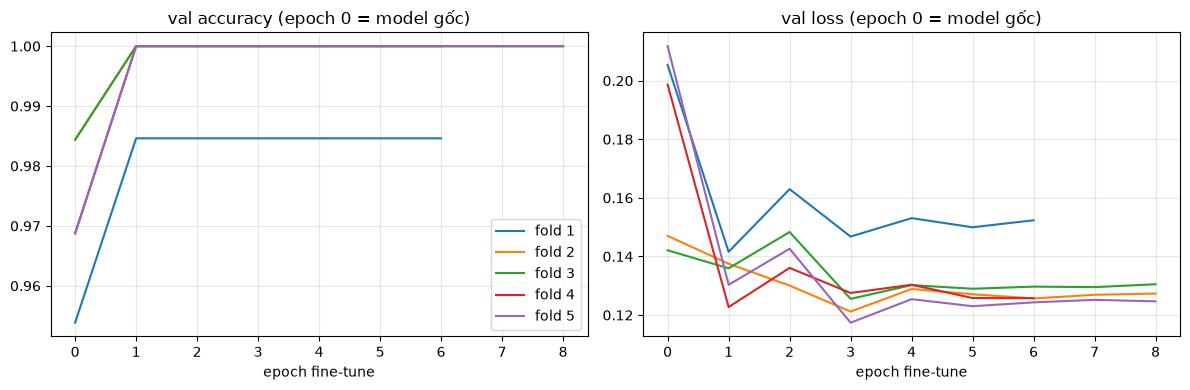

Đối thủ gần nhất trên mẫu validation gốc:
  cảm ơn → xin chào: 3.8%
  k → h: 1.7%
  dấu sắc → m: 1.4%
  h → k: 1.2%
  m → dấu sắc: 1.2%
  y → cảm ơn: 1.1%
  n → m: 0.6%
  o → địa chỉ: 0.6%
  dấu huyền → h: 0.6%
  g → h: 0.5%


In [12]:
import matplotlib.pyplot as plt

print(f"{'Fold':<6}{'train':>7}{'val':>6}{'acc gốc':>10}{'acc mới':>10}{'loss gốc':>10}{'loss mới':>10}{'best ep':>9}{'giây':>7}")
for r in per_fold:
    print(f"{r['fold']:<6}{r['n_train']:>7}{r['n_val']:>6}{r['base_val_acc']:>10.3f}{r['val_acc']:>10.3f}"
          f"{r['base_val_loss']:>10.3f}{r['val_loss']:>10.3f}{r['best_epoch']:>9}{r['seconds']:>7.0f}"
          + ("  (giữ model gốc)" if r.get("skipped") else ""))

histories = [i["history"] for i in infos if i.get("history")]
if histories:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for f, (info, hist) in enumerate(zip(infos, [i.get("history", []) for i in infos])):
        if not hist:
            continue
        ep = [0] + [h["epoch"] for h in hist]
        ax[0].plot(ep, [base_val[f]["acc"]] + [h["val_acc"] for h in hist], label=f"fold {f + 1}")
        ax[1].plot(ep, [base_val[f]["loss"]] + [h["val_loss"] for h in hist])
    ax[0].set_title("val accuracy (epoch 0 = model gốc)"); ax[0].legend()
    ax[1].set_title("val loss (epoch 0 = model gốc)")
    for a in ax:
        a.set_xlabel("epoch fine-tune"); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

print('Đối thủ gần nhất trên mẫu validation gốc:')
for pair in rivals[:10]:
    print(f"  {pair['actual']} → {pair['rival']}: {pair['mean_rival_probability']:.1%}")

## 7 · Kiểm tra nhanh model đã lưu
Các mẫu dưới đây model toàn bộ dữ liệu đã **thấy khi train** — chỉ kiểm tra pipeline nạp/dự đoán, không phải thước đo độ chính xác.
`realtime_predict.ipynb` / `VSLPredictor()` mặc định dùng `runs/best`, tức là run vừa lưu (chỉ 5 run gần nhất được giữ lại).

In [13]:
ens, ck_new = tv.load_ensemble(OUT_DIR / "ensemble.pt")
print(f"Đã nạp ensemble: {len(ens.models)} model | T={ck_new['temperature']:.2f} | ngưỡng từ chối={ck_new['reject_threshold']:.2f}")
rng = np.random.default_rng(0)
originals = np.where(validation_mask)[0]
for i in rng.choice(originals, size=min(5, len(originals)), replace=False):
    top = tv.predict_topk(ens, X[i], ck_new["classes"], k=3, reject_threshold=ck_new["reject_threshold"])[0]
    print(f"thật: {base_classes[y[i]]:<20} -> " + ", ".join(f"{n} {p:.2f}" for n, p in top))

Đã nạp ensemble: 6 model | T=1.00 | ngưỡng từ chối=0.20
thật: r                    -> r 0.91, toi 0.00, dấu â,ô,ê 0.00
thật: m                    -> m 0.80, o 0.01, dấu â,ô,ê 0.01
thật: g                    -> g 0.92, h 0.00, dấu sắc 0.00
thật: h                    -> h 0.81, o 0.01, u 0.01
thật: u                    -> u 0.92, a 0.00, dấu ơ,ư 0.00
